# ASDKL manuscript figures — executable, source-traceable notebook

Run from the repository root after the experiments listed in `REPRODUCE.md` have completed. This notebook contains the reproducible plotting workflow for manuscript Figures 2–6 and Appendix Figures C1–C2. Figures 2–6 copies the architecture artwork currently referenced by the manuscript; it is stored under `figure/assets/`. Figures 2–6 and C1–C2 read model-generated source files under `results/`. No metric is supplied by a hard-coded manuscript value. Each figure cell writes PDF and SVG, plus a PNG preview, to `results/generated_figures/`. The notebook stores displayed previews after execution. Model and dataset files are not distributed in this repository.

Chart labels, ticks, legends and panel labels use a consistent 13 pt source setting and are checked to remain at least 9 pt at the manuscript's displayed width; verify the compiled PDF whenever the insertion width changes. Colours convey distinct variables/methods and never replace numeric axes or labels.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

REPO = Path.cwd().resolve()
if not (REPO / 'methods' / 'ASDKL' / 'asdkl.py').exists():
    REPO = REPO.parent
assert (REPO / 'methods' / 'ASDKL' / 'asdkl.py').exists(), 'Open this notebook from the repository root or figure/ directory.'
OUT = REPO / 'results' / 'generated_figures'
OUT.mkdir(parents=True, exist_ok=True)
SEEDS = (1042, 1052, 1062, 1072, 1082)
mpl.rcParams.update({'font.family':'sans-serif', 'font.sans-serif':['DejaVu Sans','Arial'],
    'font.size':13, 'axes.titlesize':13, 'axes.labelsize':13,
    'xtick.labelsize':13, 'ytick.labelsize':13, 'legend.fontsize':13,
    'pdf.fonttype':42, 'svg.fonttype':'none', 'axes.spines.top':False,
    'axes.spines.right':False, 'savefig.facecolor':'white'})

def save_figure(fig, stem):
    for extension in ('pdf', 'svg', 'png'):
        fig.savefig(OUT / f'{stem}.{extension}', dpi=300, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)


## Figures 2–4 — synthetic field and spatial comparisons

The source CSVs are created by `experiments/make_spatial_figures_epoch300.py` from the original data and saved model predictions. Common scales are used for observations/predictions; residuals use zero-centred scales. Display percentile clipping does not change metrics.

In [3]:
"""Regenerate the manuscript figures from the CSV files in ``results/spatial_figure_source_data``.

The CSVs are generated from source data and held-out predictions by
``experiments/make_spatial_figures_epoch300.py``. This cell uses those
model-derived CSVs only for plotting; the reproduction workflow starts from
the original datasets as documented in ``REPRODUCE.md``.
"""
from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd


HERE = REPO / "figure"
DATA = REPO / "results" / "spatial_figure_source_data"
DEFAULT_OUTPUT = OUT
BLUE = "#2C6F93"
TEAL = "#65A695"
RED = "#B6493A"
GRID = "#E5EAEE"

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 13,
    "axes.titlesize": 13,
    "axes.labelsize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.7,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


def panel_label(ax, label: str) -> None:
    method = ax.text2D if hasattr(ax, "text2D") else ax.text
    method(0.015, 0.985, label, transform=ax.transAxes, va="top",
           fontweight="bold", fontsize=13,
           bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 0.4})


def export(fig, output: Path, stem: str, formats: list[str]) -> None:
    output.mkdir(parents=True, exist_ok=True)
    for extension in formats:
        dpi = 600 if extension == "tiff" else 300
        fig.savefig(output / f"{stem}.{extension}", dpi=dpi,
                    bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)


def synthetic_field(output: Path, formats: list[str]) -> None:
    frame = pd.read_csv(DATA / "synthetic_visualization_seed1042.csv")
    fig = plt.figure(figsize=(7.2, 3.5))
    panel_x = (0.055, 0.400, 0.745)
    panel_y, panel_w, panel_h = 0.30, 0.230, 0.49
    axes = []
    for index, x in enumerate(panel_x):
        rect = (x, panel_y, panel_w, panel_h)
        if index == 0:
            ax = fig.add_axes(rect, projection="3d")
            ax.set_box_aspect((1, 1, 0.65), zoom=0.86)
        else:
            ax = fig.add_axes(rect)
            ax.set_box_aspect(1)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
        axes.append(ax)

    ax3d, ax_b, ax_c = axes
    latent_min = float(frame.latent_spatial_component.min())
    latent_max = float(frame.latent_spatial_component.max())
    surface = ax3d.plot_trisurf(frame.s1, frame.s2, frame.latent_spatial_component,
                                cmap="viridis", vmin=latent_min, vmax=latent_max,
                                linewidth=0, antialiased=True)
    ax3d.set_title("Latent component", fontweight="bold", pad=12)
    ax3d.set_xlabel("s₁")
    ax3d.set_ylabel("s₂")
    ax3d.set_zlabel("")
    ax3d.tick_params(labelsize=13, pad=0)
    ax3d.set_xticks([0, 1]); ax3d.set_yticks([0, 1])
    ax3d.xaxis.label.set_size(13)
    ax3d.yaxis.label.set_size(13)
    panel_label(ax3d, "a")

    colourbars = [(panel_x[0], surface, "Latent value")]

    panels = ((ax_b, frame.latent_spatial_component, "Spatial regimes", "Latent value", "b"),
              (ax_c, frame.response, "Sampled response", "Response", "c"))
    for ax, values, title, scale_label, panel in panels:
        shared_scale = {"vmin": latent_min, "vmax": latent_max} if panel == "b" else {"vmin": float(np.percentile(values, 1)), "vmax": float(np.percentile(values, 99))}
        points = ax.scatter(frame.s1, frame.s2, c=values,
                            cmap="viridis", s=8, linewidth=0, **shared_scale)
        ax.set_title(title, fontweight="bold", pad=12)
        ax.set_xlabel("s₁")
        ax.set_ylabel("s₂")
        panel_label(ax, panel)
        colourbars.append((panel_x[1] if panel == "b" else panel_x[2], points, scale_label))

    for x, artist, scale_label in colourbars:
        cax = fig.add_axes((x, 0.08, panel_w, 0.022))
        cbar = fig.colorbar(artist, cax=cax, orientation="horizontal")
        cbar.set_label(scale_label, labelpad=2)
        cbar.ax.tick_params(labelsize=13, pad=1)

    export(fig, output, "synthetic_field_visualization_epoch300", formats)


def lucas_comparison(output: Path, formats: list[str]) -> None:
    frame = pd.read_csv(DATA / "lucas_full_spatial_comparison_seed1042.csv")
    observed = frame.observed_log1p_OC.to_numpy()
    asdkl = frame.ASDKL_prediction.to_numpy()
    hist = frame.HistGBR_prediction.to_numpy()
    asdkl_residual = frame.ASDKL_residual_observed_minus_prediction.to_numpy()
    hist_residual = frame.HistGBR_residual_observed_minus_prediction.to_numpy()
    lo, hi = np.percentile(np.r_[observed, asdkl, hist], [1, 99])
    residual_limit = np.percentile(np.abs(np.r_[asdkl_residual, hist_residual]), 99)
    fig = plt.figure(figsize=(7.2, 5.6), constrained_layout=True)
    grid = fig.add_gridspec(2, 3, width_ratios=[1.08, 1, 1])
    axes = [fig.add_subplot(grid[:, 0]), fig.add_subplot(grid[0, 1]),
            fig.add_subplot(grid[0, 2]), fig.add_subplot(grid[1, 1]),
            fig.add_subplot(grid[1, 2])]
    values = [observed, asdkl, hist, asdkl_residual, hist_residual]
    titles = ["Observed test\nresponses", "ASDKL\nprediction",
          "HistGBR\nprediction", "ASDKL\nresidual", "HistGBR\nresidual"]
    for index, (ax, values_i, title) in enumerate(zip(axes, values, titles)):
        if index < 3:
            artist = ax.scatter(frame.longitude, frame.latitude, c=values_i,
                                cmap="viridis", vmin=lo, vmax=hi, s=4, linewidth=0)
        else:
            artist = ax.scatter(frame.longitude, frame.latitude, c=values_i,
                                cmap="coolwarm", norm=TwoSlopeNorm(0, -residual_limit, residual_limit),
                                s=4, linewidth=0)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
        ax.grid(color=GRID, linewidth=0.4); panel_label(ax, chr(97 + index))
    fig.colorbar(axes[2].collections[0], ax=axes[1:3], fraction=0.035, pad=0.02,
                 label=r"$\log(1+\mathrm{OC})$")
    fig.colorbar(axes[4].collections[0], ax=axes[3:5], fraction=0.035, pad=0.02,
                 label="Residual (observed − predicted)")
    export(fig, output, "lucas_full_asdkl_histgbr_comparison_epoch300", formats)


def california_map(output: Path, formats: list[str]) -> None:
    frame = pd.read_csv(DATA / "california_full_spatial_visualization_seed1042.csv")
    observed = frame.observed_median_house_value.to_numpy()
    predicted = frame.ASDKL_prediction.to_numpy()
    residual = frame.residual_observed_minus_prediction.to_numpy()
    lo, hi = np.percentile(np.r_[observed, predicted], [1, 99])
    residual_limit = np.percentile(np.abs(residual), 99)
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.1), constrained_layout=True)
    titles = ["Observed", "ASDKL", "Residual"]
    for index, (ax, values, title) in enumerate(zip(axes, [observed, predicted, residual], titles)):
        if index < 2:
            ax.scatter(frame.longitude, frame.latitude, c=values, cmap="viridis",
                       vmin=lo, vmax=hi, s=5, linewidth=0)
        else:
            ax.scatter(frame.longitude, frame.latitude, c=values, cmap="coolwarm",
                       norm=TwoSlopeNorm(0, -residual_limit, residual_limit), s=5, linewidth=0)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
        ax.grid(color=GRID, linewidth=0.4); panel_label(ax, chr(97 + index))
    for ax in axes[:2]:
        fig.colorbar(ax.collections[0], ax=ax, orientation="horizontal", fraction=0.06, pad=0.12,
                     label="Value ($100,000)")
    fig.colorbar(axes[2].collections[0], ax=axes[2], orientation="horizontal",
                 fraction=0.06, pad=0.12, label="Residual ($100,000)")
    export(fig, output, "california_full_spatial_visualization_epoch300", formats)




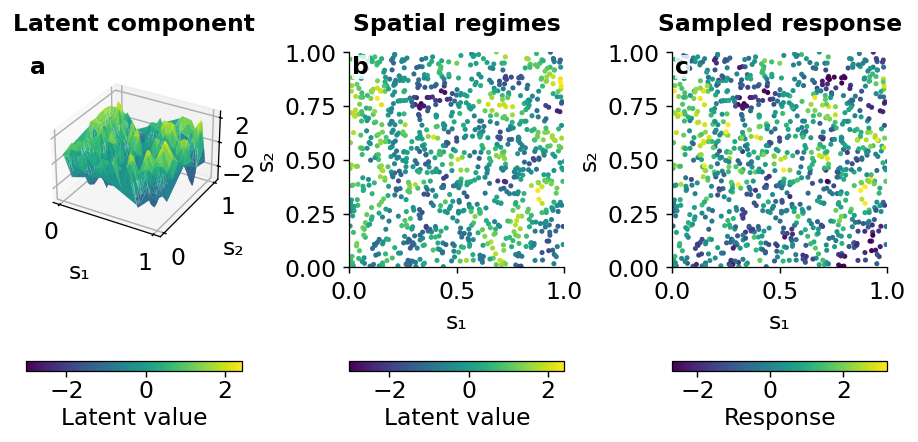

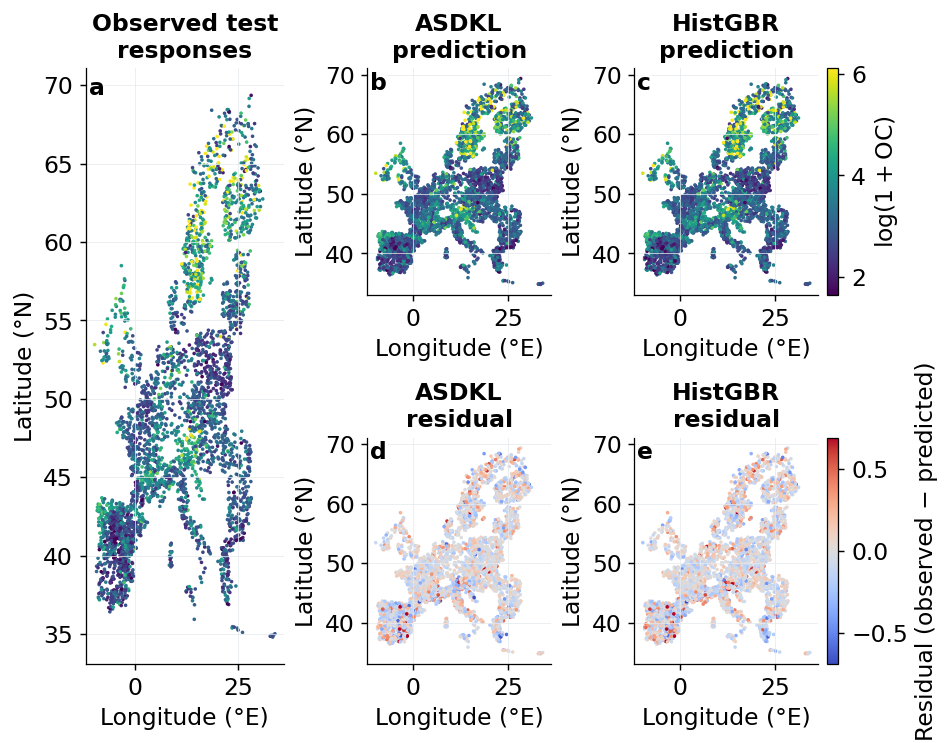

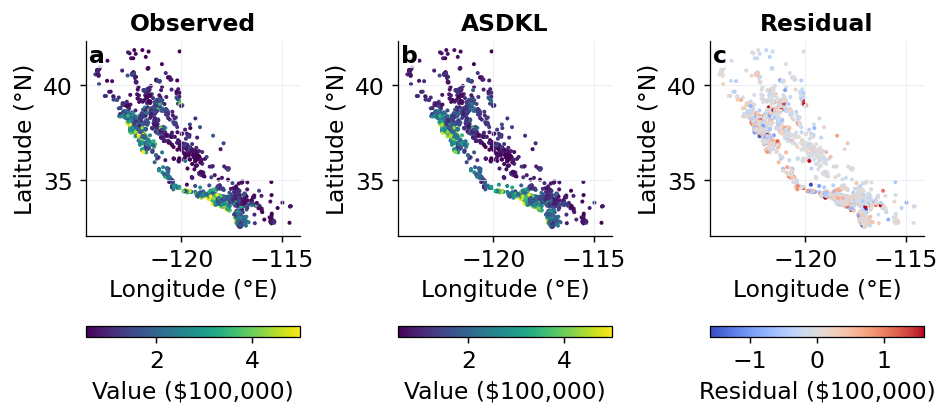

In [4]:
for filename in ('synthetic_visualization_seed1042.csv', 'lucas_full_spatial_comparison_seed1042.csv',
                 'california_full_spatial_visualization_seed1042.csv'):
    assert (DATA / filename).exists(), f'Missing {filename}; see REPRODUCE.md (Figures 2–4).'
synthetic_field(OUT, ['pdf','svg','png'])
lucas_comparison(OUT, ['pdf','svg','png'])
california_map(OUT, ['pdf','svg','png'])

## Figure 5 — EPA observation-density learning curve

Reads every seed and training fraction from the experiment output. The black curve is the five-seed mean; the band uses the two-sided 95% t interval of the mean.

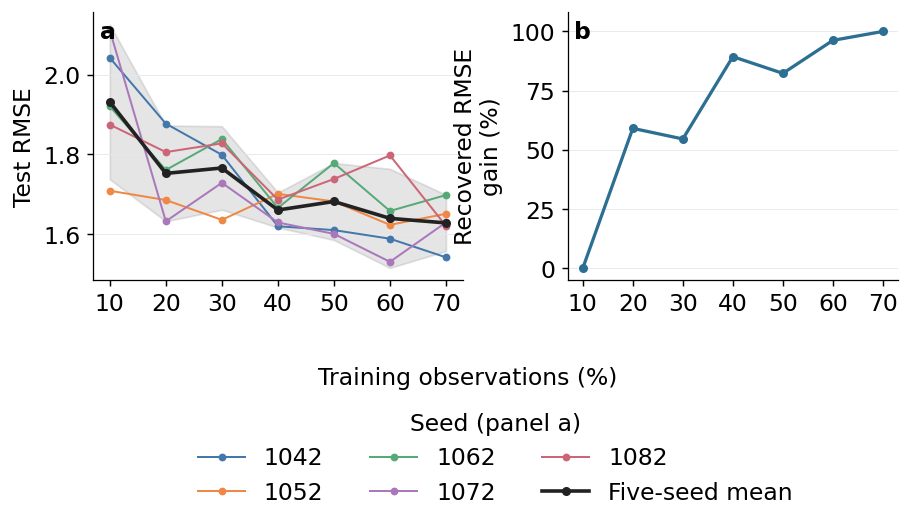

In [5]:
raw = pd.read_csv(REPO/'results'/'epa_sparse_fraction_fixedtest'/'asdkl_fraction_results.csv')
mpl.rcParams.update({'font.size':13,'axes.labelsize':13,'xtick.labelsize':13,
                     'ytick.labelsize':13,'legend.fontsize':13})
assert set(SEEDS).issubset(set(raw.seed)), 'EPA sparse results must include all five evaluation seeds.'
grp = raw.groupby('training_fraction_pct').rmse.agg(['mean','std','count']).sort_index()
x=grp.index.to_numpy(float); mean=grp['mean'].to_numpy(float)
ci=2.776*grp['std'].to_numpy(float)/np.sqrt(grp['count'].to_numpy(float))
fig, axes=plt.subplots(1,2,figsize=(7.2,4.2),gridspec_kw={'width_ratios':[1.12,1]})
fig.subplots_adjust(left=.10,right=.96,top=.96,bottom=.47,wspace=.30)
seed_colors=['#4477AA','#EE8844','#55AA77','#AA77BB','#CC6677']
for color,(seed,rows) in zip(seed_colors,raw.groupby('seed')):
    rows=rows.sort_values('training_fraction_pct')
    axes[0].plot(rows.training_fraction_pct,rows.rmse,'o-',lw=1.1,ms=3.3,color=color,label=str(seed))
axes[0].plot(x,mean,'o-',lw=2,ms=4,color='#222222',label='Five-seed mean')
axes[0].fill_between(x,mean-ci,mean+ci,color='#555555',alpha=.15)
gain=100*(mean[0]-mean)/(mean[0]-mean[-1])
axes[1].plot(x,gain,'o-',lw=1.8,ms=4,color='#2C6F93')
for label,axis in zip('ab',axes):
    axis.text(.02,.97,label,transform=axis.transAxes,fontsize=13,weight='bold',va='top')
    axis.set_xticks(x)
    axis.grid(axis='y',color='#E5EAEE',lw=.5)
axes[0].set_ylabel('Test RMSE')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc='lower center', bbox_to_anchor=(.53,.02),
           title='Seed (panel a)', fontsize=13, title_fontsize=13,
           frameon=False)
axes[1].set_ylabel('Recovered RMSE\ngain (%)'); axes[1].set_ylim(-5,108)
fig.supxlabel('Training observations (%)', y=.27, fontsize=13)
save_figure(fig,'epa_sparse_learning_curve')

## Figure 6 — paired structural and module ablations

Each coloured dot is one evaluation seed. Diamonds indicate the mean percentage change in test RMSE relative to the same-seed complete ASDKL run; horizontal bars show sample standard deviations.

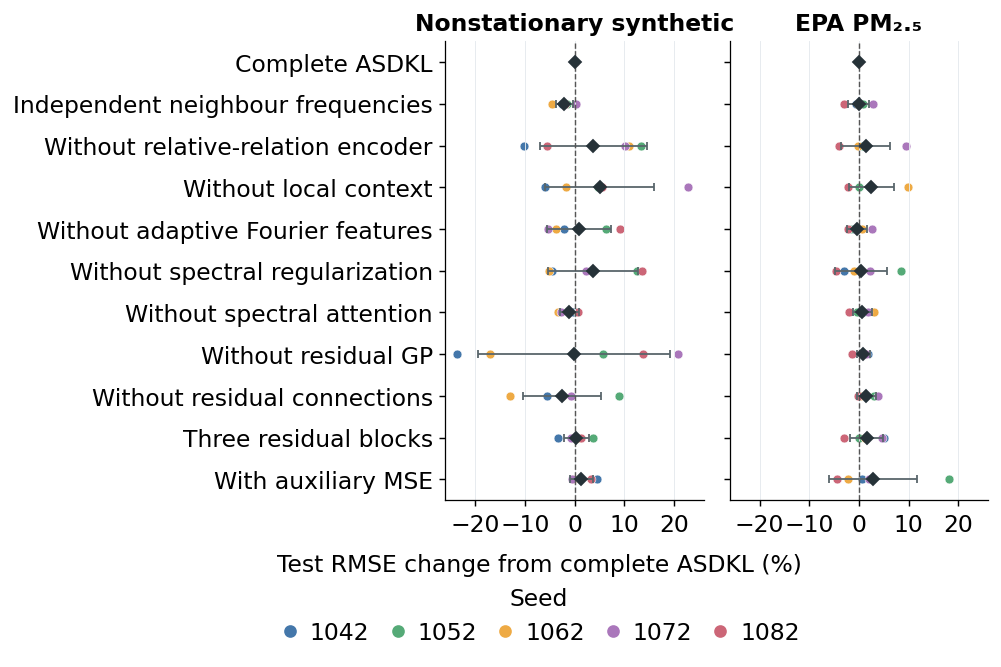

In [6]:
source=pd.read_csv(REPO/'results'/'revision14_summary'/'figure6_source.csv')
mpl.rcParams.update({'font.size':13,'axes.labelsize':13,'axes.titlesize':13,
                     'xtick.labelsize':13,'ytick.labelsize':13,'legend.fontsize':13})
order=['six_block_reference','independent_frequencies','no_relation_encoder','no_context','no_fourier',
       'no_spectral_regularization','no_spectral_attention','no_gp','no_residual_connections',
       'three_residual_blocks','auxiliary_mse']
labels=['Complete ASDKL','Independent neighbour frequencies','Without relative-relation encoder',
        'Without local context','Without adaptive Fourier features','Without spectral regularization',
        'Without spectral attention','Without residual GP','Without residual connections',
        'Three residual blocks','With auxiliary MSE']
assert set(order).issubset(set(source.group))
fig,axes=plt.subplots(1,2,figsize=(7.2,5.35),sharey=True)
fig.subplots_adjust(left=.40,right=.98,top=.91,bottom=.25,wspace=.10)
seed_colors=dict(zip(SEEDS,['#4477AA','#55AA77','#EEAA44','#AA77BB','#CC6677']))
for ax,dataset,title in zip(axes,['synthetic','pm25'],['Nonstationary synthetic','EPA PM₂.₅']):
    subset=source[source.dataset.eq(dataset)]
    for y,group in enumerate(order):
        vals=subset[subset.group.eq(group)].sort_values('seed')
        assert len(vals)==5, (dataset,group,len(vals))
        for _,row in vals.iterrows():
            ax.scatter(row.delta,y,s=24,color=seed_colors[int(row.seed)],edgecolor='white',linewidth=.3)
        ax.errorbar(vals.delta.mean(),y,xerr=vals.delta.std(ddof=1),fmt='D',ms=5,
                    color='#263238',ecolor='#59666B',elinewidth=1,capsize=2)
    ax.axvline(0,color='#555555',lw=.8,ls='--'); ax.set_title(title,weight='bold')
    ax.set_xlim(-26,26)
    ax.set_xticks([-20,-10,0,10,20])
    ax.grid(axis='x',color='#E5EAEE',lw=.5)
axes[0].set_yticks(range(len(order)),labels); axes[0].invert_yaxis()
fig.supxlabel('Test RMSE change from complete ASDKL (%)',y=.14,fontsize=13)
handles=[plt.Line2D([],[],marker='o',ls='',color=color,label=str(seed),ms=6) for seed,color in seed_colors.items()]
fig.legend(handles=handles,title='Seed',ncol=5,loc='lower center',bbox_to_anchor=(.5,.012),fontsize=13,title_fontsize=13,
           columnspacing=.7,handletextpad=.35,handlelength=1.0)
save_figure(fig,'ablation_epoch300_bar')

## Appendix Figure C1 — convergence

Reads five training histories and their validation-selected checkpoint epochs directly from model run JSON files.

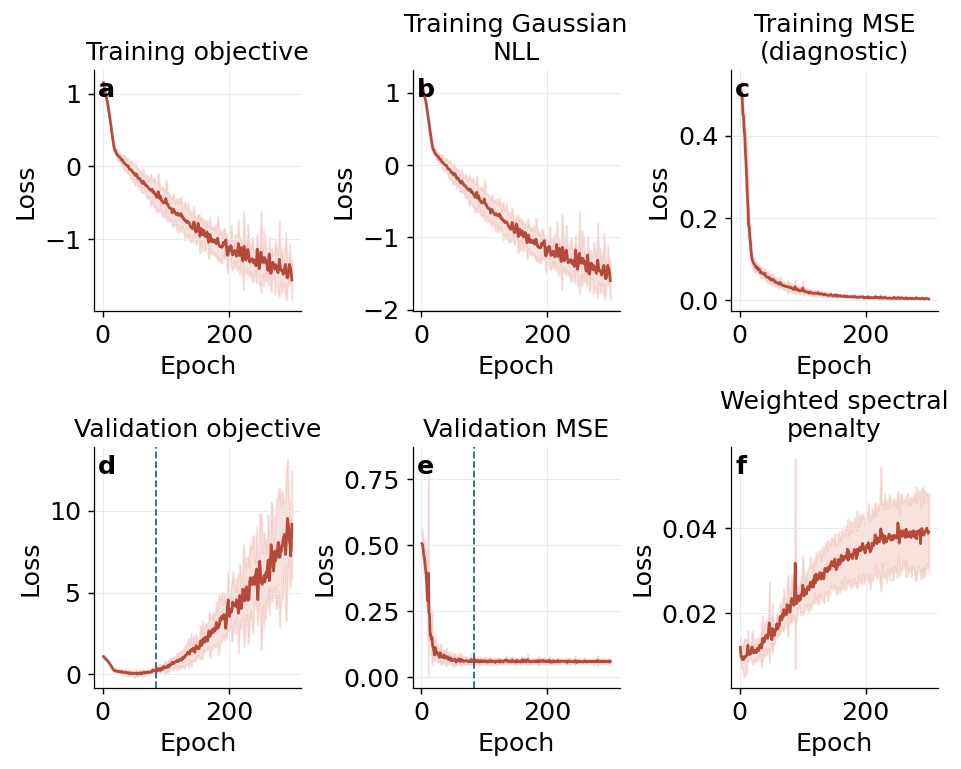

In [7]:
histories=[]; best_epochs=[]
mpl.rcParams.update({'font.size':14,'axes.labelsize':14,'axes.titlesize':14,
                     'xtick.labelsize':14,'ytick.labelsize':14})
for seed in SEEDS:
    path=REPO/'results'/'revision14_shared_relation'/'six_block_reference'/'synthetic'/f'seed_{seed}'/'synthetic_run.json'
    item=json.loads(path.read_text(encoding='utf-8'))
    histories.append(item['training_history']); best_epochs.append(int(item['best_epoch']))
panels=[('total','Training objective',False),('nll','Training Gaussian\nNLL',False),
        ('mse','Training MSE\n(diagnostic)',True),('val_total','Validation objective',False),
        ('val_mse','Validation MSE',True),('spectral','Weighted spectral\npenalty',True)]
fig,axes=plt.subplots(2,3,figsize=(7.2,5.8),layout='constrained')
for index,(ax,(key,title,nonnegative)) in enumerate(zip(axes.flat,panels)):
    values=np.asarray([h[key] for h in histories],dtype=float)
    if key=='spectral': values*=.1
    epoch=np.asarray(histories[0]['epoch'],dtype=float)
    mean=np.nanmean(values,axis=0); ci=2.776*np.nanstd(values,axis=0,ddof=1)/np.sqrt(len(SEEDS))
    lower=np.maximum(0,mean-ci) if nonnegative else mean-ci
    ax.plot(epoch,mean,color='#B6493A',lw=1.5)
    ax.fill_between(epoch,lower,mean+ci,color='#E9A99F',alpha=.35)
    if key in {'val_total','val_mse'}: ax.axvline(np.median(best_epochs),color='#236987',lw=1,ls='--')
    ax.set(title=title,xlabel='Epoch',ylabel='Loss'); ax.grid(color='#E5EAEE',lw=.5)
    ax.text(.02,.97,chr(97+index),transform=ax.transAxes,weight='bold',fontsize=14,va='top')
save_figure(fig,'synthetic_convergence_epoch300')

## Appendix Figure C2 — validation-only sensitivity

`experiments/summarize_revision14.py` computes this source from each sensitivity run and the default model's validation RMSE. Test targets are not used to select settings.

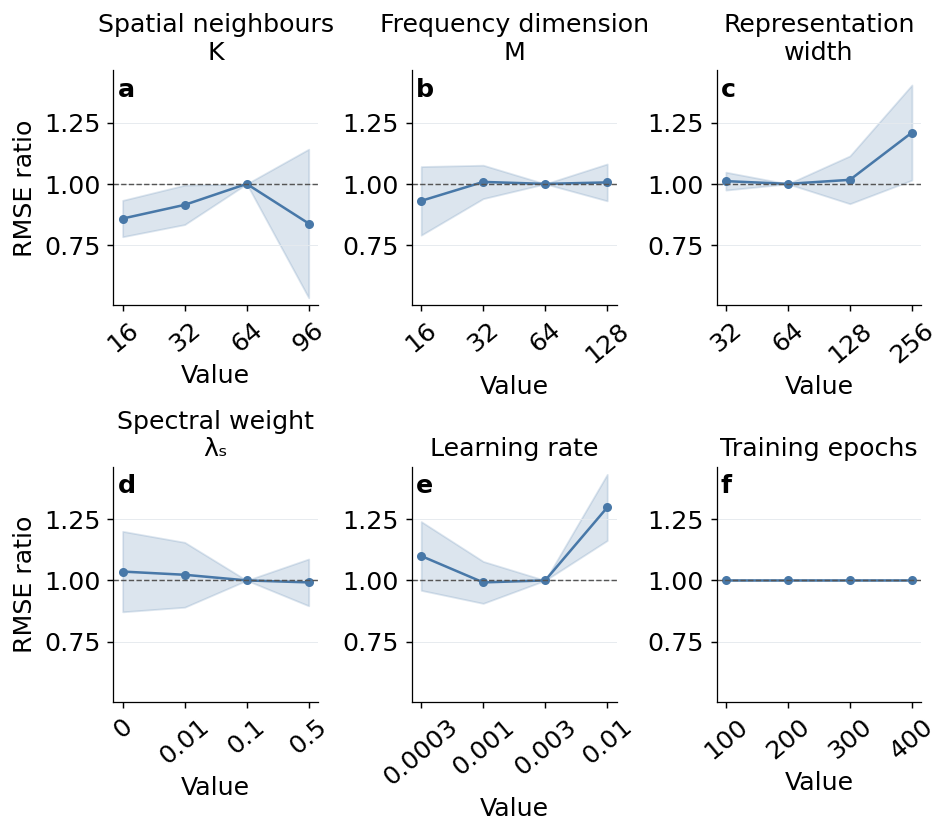

In [8]:
summ=pd.read_csv(REPO/'results'/'revision14_summary'/'sensitivity_summary.csv')
families=['neighbors','freq_dim','hidden_dim','lambda_spectral','lr','epochs']
titles={'neighbors':'Spatial neighbours\nK','freq_dim':'Frequency dimension\nM',
        'hidden_dim':'Representation\nwidth','lambda_spectral':'Spectral weight\nλₛ',
        'lr':'Learning rate','epochs':'Training epochs'}
all_ci=2.776*summ.sd/np.sqrt(summ.n)
ymin=float((summ['mean']-all_ci).min()-.03); ymax=float((summ['mean']+all_ci).max()+.03)
fig,axes=plt.subplots(2,3,figsize=(7.2,6.3),layout='constrained')
for index,(ax,family) in enumerate(zip(axes.flat,families)):
    grp=summ[summ.family.eq(family)].sort_values('value')
    assert len(grp)>1, family
    x=np.arange(len(grp)); values=grp['mean'].to_numpy(float)
    ci=2.776*grp.sd.to_numpy(float)/np.sqrt(grp.n.to_numpy(float))
    ax.fill_between(x,values-ci,values+ci,color='#4878A8',alpha=.19)
    ax.plot(x,values,'o-',lw=1.4,ms=4,color='#4878A8')
    ax.axhline(1,color='#555555',lw=.8,ls='--')
    ax.set_xticks(x,[f'{value:g}' for value in grp.value],rotation=40)
    ax.set(title=titles[family],xlabel='Value',
           ylabel='RMSE ratio' if index % 3 == 0 else '',
           ylim=(ymin,ymax))
    ax.grid(axis='y',color='#E5EAEE',lw=.5)
    ax.text(.02,.97,chr(97+index),transform=ax.transAxes,weight='bold',fontsize=14,va='top')
save_figure(fig,'hyperparameter_sensitivity_synthetic_epoch300')